# Airline Sentiment Analysis: Machine Learning Workflow

End-to-end text-classification workflow that predicts whether an airline-related tweet is **negative**, **neutral** or **positive**.

| Phase | Content |
| :--- | :--- |
| 1 | Business understanding |
| 2 | Data understanding (shape, missing values, duplicates, leakage check) |
| 3 | Exploratory data analysis |
| 4 | Text preprocessing and stratified train / validation / test split |
| 5 | Feature engineering (TF-IDF) and model training with `GridSearchCV` |
| 6 | Evaluation, error analysis, interpretability and final test-set score |
| 7 | Topic modelling (LDA) on negative tweets and model serialization |
| 8 | Summary of findings |

**Requirements:** place `Tweets.csv` in the same folder as this notebook (in Colab: upload it to `/content`). Running the notebook creates `best_sentiment_pipeline.joblib`, which is used by `app.py` and `dashboard.py`.

# Phase 1: Business Understanding

## 1. Business Context & Problem Statement
In the highly competitive airline industry, customer satisfaction and brand reputation are critical drivers of customer loyalty and revenue. Today, passengers frequently turn to social media platforms, particularly Twitter/X, to express their immediate feedback, share experiences, or seek assistance during disruptions (e.g., flight delays, cancellations, baggage issues).

Historically, sentiment analysis of these tweets has been handled manually or with basic keyword-matching tools. However, manual sentiment analysis is:
- **Slow and unscalable:** Human agents cannot keep pace with the massive volume of real-time social media mentions, leading to backlogs.
- **Inconsistent:** Different agents may interpret sentiment subjectively, reducing data reliability.
- **Reactive rather than proactive:** Delayed insights prevent operational teams from addressing unfolding crises before they escalate.

Developing an automated, machine learning-driven Sentiment Analysis System allows the airline to instantly categorize customer feedback into Positive, Neutral, or Negative classes, enabling immediate escalation and systemic analytical reporting.

## 2. Target Users & Value Proposition
Different stakeholders within the airline will interact with this system:

*   **Customer Experience (CX) & Operations Managers:**
    *   *Value:* Gain real-time visibility into systemic issues (e.g., check-in delays at a specific airport or recurring service complaints) to deploy operational adjustments rapidly.
*   **Brand Reputation & Public Relations (PR) Teams:**
    *   *Value:* Detect early warning signs of public relations crises or sudden spikes in negative sentiment, allowing for immediate strategic communication.
*   **Customer Support Agents:**
    *   *Value:* Prioritize incoming support requests based on urgency and severe negative sentiment, accelerating resolution times for highly distressed passengers.

## 3. Key Performance Indicators (KPIs) & Metrics
To evaluate success, we must distinguish between business-oriented outcomes and machine learning performance metrics:

### Business KPIs
*   **Response Time Reduction:** Decrease the average time taken by customer support to respond to highly critical negative tweets.
*   **Net Sentiment Score Improvement:** Drive a positive shift in overall brand sentiment over time through timely crisis mitigation and feedback loops.
*   **Customer Retention & Escalation Deflection:** Lower the volume of formal support tickets by resolving complaints directly on social channels.

### Machine Learning Metrics
*   **F1-Score (Macro & Per-Class):** Ensures balanced performance across positive, neutral, and negative classes, which is critical given class imbalances (typically negative tweets outnumber positive ones).
*   **Precision:** Minimizes false positives (e.g., incorrectly flagging a positive tweet as negative), which avoids wasting customer service resources.
*   **Recall:** Minimizes false negatives, ensuring critical negative complaints are not missed.

## 4. Project Boundaries, Assumptions & Limitations
*   **Platform Bias:** Twitter/X users represent a specific demographic slice of the passenger base, which may skew younger, tech-savvy, or highly vocal compared to the general customer population.
*   **Sarcasm & Slang:** Sarcastic expressions (e.g., "Thanks for losing my bags again, great service!") present a challenge for standard NLP models and may result in misclassification.
*   **Context & Multimodality:** Tweets often contain emojis, images, or external links that add essential context. This project primarily targets text-based sentiment analysis, representing a limitation in parsing multi-modal posts.

# Phase 2: Data Understanding

Load `Tweets.csv` and inspect its shape, data types, missing values, duplicates, class distribution and text length. The last step flags columns that would leak the target.

In [1]:
import pandas as pd
import numpy as np

# 1. Load the dataset
df = pd.read_csv('Tweets.csv')

# 2. Basic structure
print('=== Dataset Shape ===')
print(df.shape)
print('\n=== Column Info ===')
df.info()

# 3. Missing values
print('\n=== Missing Values ===')
missing_count = df.isnull().sum()
missing_percent = (df.isnull().sum() / len(df)) * 100
missing_df = pd.DataFrame({'Missing Count': missing_count, 'Percentage (%)': missing_percent})
print(missing_df.sort_values(by='Missing Count', ascending=False))

# 4. Duplicates
print('\n=== Duplicate Rows ===')
duplicates_count = df.duplicated().sum()
print(f'Number of completely duplicated rows: {duplicates_count}')

# 5. Target distribution ('airline_sentiment')
print('\n=== Target Distribution (airline_sentiment) ===')
if 'airline_sentiment' in df.columns:
    counts = df['airline_sentiment'].value_counts()
    pct = df['airline_sentiment'].value_counts(normalize=True) * 100
    dist_df = pd.DataFrame({'Count': counts, 'Percentage (%)': pct})
    print(dist_df)
else:
    print('airline_sentiment column not found!')

# 6. Text lengths
if 'text' in df.columns:
    print('\n=== Text Length Statistics ===')
    df['char_length'] = df['text'].astype(str).apply(len)
    df['word_length'] = df['text'].astype(str).apply(lambda x: len(x.split()))
    print(df[['char_length', 'word_length']].describe())
else:
    print('text column not found!')

# 7. Check for potential data leakage indicators
print('\n=== Data Leakage Check: Column Meanings ===')
for col in df.columns:
    print(f'- {col}')
print('\nAnalysis: Columns like "negativereason" and "negativereason_confidence" are only present or populated when "airline_sentiment" is "negative". These columns are direct leakages/indicators of the target variable and should not be used as features for training models to predict general sentiment.')

=== Dataset Shape ===
(14640, 15)

=== Column Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14640 entries, 0 to 14639
Data columns (total 15 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   tweet_id                      14640 non-null  int64  
 1   airline_sentiment             14640 non-null  object 
 2   airline_sentiment_confidence  14640 non-null  float64
 3   negativereason                9178 non-null   object 
 4   negativereason_confidence     10522 non-null  float64
 5   airline                       14640 non-null  object 
 6   airline_sentiment_gold        40 non-null     object 
 7   name                          14640 non-null  object 
 8   negativereason_gold           32 non-null     object 
 9   retweet_count                 14640 non-null  int64  
 10  text                          14640 non-null  object 
 11  tweet_coord                   1019 non-null   object 
 12  tweet

# Phase 3: Exploratory Data Analysis (EDA)

Sentiment distribution, sentiment by airline, reasons behind negative tweets, and tweet length by sentiment.

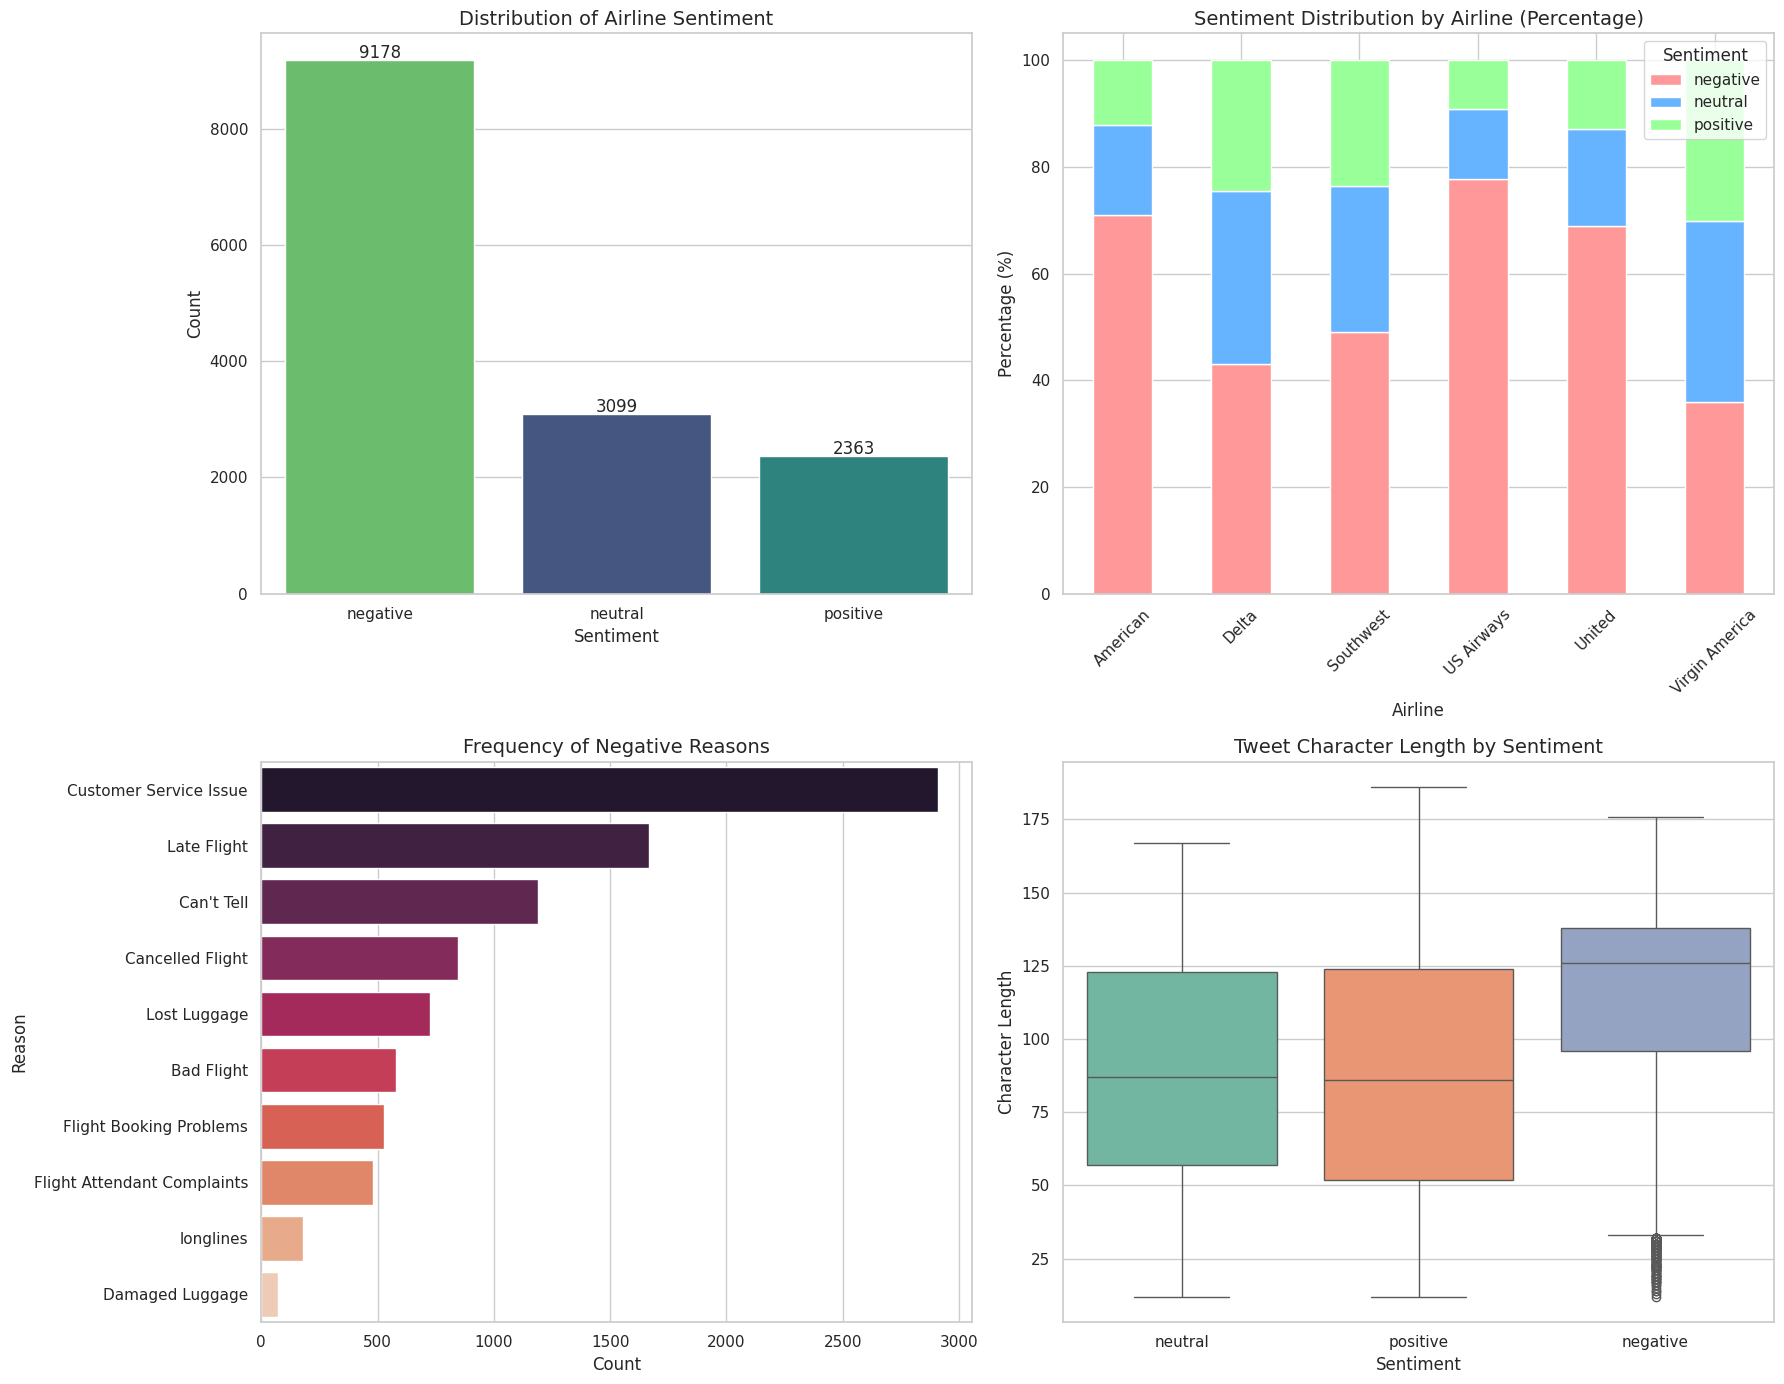

=== Text Length Summary Statistics Grouped by Sentiment ===
                  char_length                                  word_length  \
                         mean        std          var min  max        mean   
airline_sentiment                                                            
negative           113.947919  30.719006   943.657307  12  176   19.686206   
neutral             87.359471  37.682903  1420.001146  12  167   14.408842   
positive            86.082945  39.482103  1558.836470  12  186   14.013119   

                                                
                        std        var min max  
airline_sentiment                               
negative           5.944701  35.339465   2  36  
neutral            6.962293  48.473531   2  31  
positive           7.039221  49.550632   2  31  


In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Set the plotting style
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (14, 10)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12

fig, axes = plt.subplots(2, 2, figsize=(18, 14))

# 1. Target Sentiment Distribution
sns.countplot(data=df, x='airline_sentiment', ax=axes[0, 0], hue='airline_sentiment', palette='viridis', order=['negative', 'neutral', 'positive'], legend=False)
axes[0, 0].set_title('Distribution of Airline Sentiment')
axes[0, 0].set_xlabel('Sentiment')
axes[0, 0].set_ylabel('Count')
for p in axes[0, 0].patches:
    if p.get_height() > 0:
        axes[0, 0].annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center', xytext=(0, 5), textcoords='offset points')

# 2. Airline vs Sentiment Cross-tabulation
airline_sentiment_pct = pd.crosstab(df['airline'], df['airline_sentiment'], normalize='index') * 100
airline_sentiment_pct.plot(kind='bar', stacked=True, ax=axes[0, 1], color=['#ff9999','#66b3ff','#99ff99'])
axes[0, 1].set_title('Sentiment Distribution by Airline (Percentage)')
axes[0, 1].set_xlabel('Airline')
axes[0, 1].set_ylabel('Percentage (%)')
axes[0, 1].legend(title='Sentiment')
axes[0, 1].tick_params(axis='x', rotation=45)

# 3. Distribution of Negative Reasons
neg_reasons = df['negativereason'].value_counts()
sns.barplot(x=neg_reasons.values, y=neg_reasons.index, ax=axes[1, 0], hue=neg_reasons.index, palette='rocket', legend=False)
axes[1, 0].set_title('Frequency of Negative Reasons')
axes[1, 0].set_xlabel('Count')
axes[1, 0].set_ylabel('Reason')

# 4. Text Length Distribution Grouped by Sentiment
sns.boxplot(data=df, x='airline_sentiment', y='char_length', ax=axes[1, 1], hue='airline_sentiment', palette='Set2', legend=False)
axes[1, 1].set_title('Tweet Character Length by Sentiment')
axes[1, 1].set_xlabel('Sentiment')
axes[1, 1].set_ylabel('Character Length')

plt.tight_layout()
plt.show()

# Detailed Descriptive Statistics
print('=== Text Length Summary Statistics Grouped by Sentiment ===')
summary_stats = df.groupby('airline_sentiment')[['char_length', 'word_length']].agg(['mean', 'std', 'var', 'min', 'max'])
print(summary_stats)

### Phase 3: Business Interpretations and Insights from EDA

#### 1. Target Sentiment Distribution
* **Finding:** The dataset is heavily imbalanced, with **62.7% (9,178 tweets)** of the comments being classified as **Negative**, while Neutral (21.2%) and Positive (16.1%) occupy significantly smaller shares.
* **Business Implications:** Customers are far more likely to tweet an airline when they encounter a problem than when they have a smooth or pleasant experience. This highlights the importance of real-time escalation and prioritizing support queues for negative sentiment to prevent public brand erosion.

#### 2. Brand Patterns & Airline Sentiment Cross-tabulation
* **Finding:** Sentiment distributions vary highly across carrier brands. **US Airways** and **American Airlines** display the worst negative sentiment ratios (77.7% and 71.0%, respectively). Conversely, **Virgin America** has the lowest negative feedback ratio (35.9%) and the highest positive ratio (30.2%).
* **Business Implications:** Best practices from Virgin America's customer experience strategy should be studied and shared. Airlines with exceptionally high negative ratios need immediate operational intervention, targeting specific high-frequency negative issue types.

#### 3. Frequency of Negative Reasons
* **Finding:** **Customer Service Issue** is by far the most dominant cause of negative tweets (~2,910 complaints), followed by **Late Flight** (~1,665 complaints) and **Cancelled Flight** (~847 complaints).
* **Business Implications:** While flight delays and cancellations are often unavoidable due to weather or air traffic control, *how* the airline communicates and manages these events (Customer Service) is the single biggest driver of customer distress. Training frontline staff, improving refund policies, and automating rebooking notifications are critical areas for operational investment.

#### 4. Character Length and Word Count Analysis by Sentiment
* **Finding:** Negative tweets are noticeably longer and have higher text density than neutral or positive ones. Negative tweets have an average length of **113.9 characters (19.7 words)** with a low variance ($\sigma^2 \approx 943.7$), while positive tweets average **86.1 characters (14.0 words)** with higher variance.
* **Business Implications:** Customers venting or explaining issues tend to write detailed, structured paragraphs describing their operational bottlenecks (flight numbers, specific issues, baggage details). Positive tweets are more transactional or quick (e.g., "Thank you! @airline"). This structural difference in text length can serve as an informative predictive feature during model training.

# Phase 4: Text Preprocessing and Data Splitting

Cleaning steps: lowercasing, URL / @mention / HTML removal, removal of digits and special characters, stop-word removal (a small **negation whitelist is kept**) and WordNet lemmatization.

Only the cleaned `text` column is used as a feature, so the leakage-prone `negativereason*` columns are excluded. The split is **stratified 70 / 15 / 15** (train / validation / test).

In [5]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.model_selection import train_test_split

# 1. Download necessary NLTK packages
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

# 2. Define robust text preprocessing function
# We will preserve important negation words to retain sentiment context
NEGATION_WORDS = {'not', 'no', 'never', 'neither', 'nor', 'none', 'cannot', "n't", 'hardly', 'scarcely', 'barely'}
STOPWORDS_SET = set(stopwords.words('english')) - NEGATION_WORDS
LEMMATIZER = WordNetLemmatizer()

def preprocess_text(text):
    if not isinstance(text, str):
        return ""

    # Convert to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r'https?:\/\/\S+|www\.\S+', '', text)

    # Remove Twitter handles/mentions (@airline, etc.)
    text = re.sub(r'@\w+', '', text)

    # Remove HTML tags/entities if any
    text = re.sub(r'<[^>]+>', '', text)

    # Remove numbers and special punctuation, but preserve words and basic spaces
    text = re.sub(r"[^a-zA-Z\s']", '', text)

    # Tokenize by whitespace
    tokens = text.split()

    # Filter stopwords (except negations) and lemmatize
    cleaned_tokens = [LEMMATIZER.lemmatize(word) for word in tokens if word not in STOPWORDS_SET]

    return " ".join(cleaned_tokens)

# 3. Clean the dataset text column
print("Applying text preprocessing (lowercasing, URLs, mentions, stop-words, negations)...")
df['cleaned_text'] = df['text'].apply(preprocess_text)

# 4. Prepare feature and target arrays, strictly avoiding leakage columns
# Keeping only relevant columns: cleaned_text as features, airline_sentiment as target
X = df['cleaned_text']
y = df['airline_sentiment']

# 5. Stratified split (70% Train, 15% Val, 15% Test)
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.15, random_state=42, stratify=y
)

# Split remaining 85% into Train (approx 70% of total) and Val (approx 15% of total)
# 15 / 85 is approximately 17.65%
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.17647, random_state=42, stratify=y_train_full
)

# 6. Verify and output results
print(f"\n=== Dataset Splits Shape ===")
print(f"Train set shape:      {X_train.shape} (Labels: {y_train.shape})")
print(f"Validation set shape: {X_val.shape} (Labels: {y_val.shape})")
print(f"Test set shape:       {X_test.shape} (Labels: {y_test.shape})")

print("\n=== Stratification Verification (Target Proportions) ===")
for name, dataset in [('Train', y_train), ('Validation', y_val), ('Test', y_test)]:
    proportions = dataset.value_counts(normalize=True) * 100
    counts = dataset.value_counts()
    print(f"\n{name} Split:")
    for idx in proportions.index:
        print(f"  {idx:<10}: {counts[idx]:<5} ({proportions[idx]:.2f}%)")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


Applying text preprocessing (lowercasing, URLs, mentions, stop-words, negations)...

=== Dataset Splits Shape ===
Train set shape:      (10248,) (Labels: (10248,))
Validation set shape: (2196,) (Labels: (2196,))
Test set shape:       (2196,) (Labels: (2196,))

=== Stratification Verification (Target Proportions) ===

Train Split:
  negative  : 6424  (62.69%)
  neutral   : 2169  (21.17%)
  positive  : 1655  (16.15%)

Validation Split:
  negative  : 1377  (62.70%)
  neutral   : 465   (21.17%)
  positive  : 354   (16.12%)

Test Split:
  negative  : 1377  (62.70%)
  neutral   : 465   (21.17%)
  positive  : 354   (16.12%)


# Phase 5: Feature Engineering and Model Training

A scikit-learn `Pipeline` combines TF-IDF (unigrams + bigrams, `min_df=3`, `max_df=0.9`) with a classifier. Naive Bayes, Logistic Regression and Linear SVC are each tuned with 5-fold `GridSearchCV`, optimising **Macro-F1**.

In [6]:
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, accuracy_score, f1_score

# 1. Define base TF-IDF configuration
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_df=0.9)

# 2. Build different pipelines
pipelines = {
    'NaiveBayes': Pipeline([
        ('tfidf', tfidf),
        ('clf', MultinomialNB())
    ]),
    'LogisticRegression': Pipeline([
        ('tfidf', tfidf),
        ('clf', LogisticRegression(max_iter=1000, random_state=42))
    ]),
    'LinearSVC': Pipeline([
        ('tfidf', tfidf),
        ('clf', LinearSVC(random_state=42))
    ])
}

# 3. Define hyperparameter grids
param_grids = {
    'NaiveBayes': {
        'clf__alpha': [0.1, 0.5, 1.0]
    },
    'LogisticRegression': {
        'clf__C': [0.1, 1.0, 10.0]
    },
    'LinearSVC': {
        'clf__C': [0.1, 1.0, 10.0]
    }
}

best_models = {}

# 4. Train and perform grid search cross-validation
for model_name, pipeline in pipelines.items():
    print(f'=== Training & Optimizing {model_name} ===')
    grid_search = GridSearchCV(
        pipeline,
        param_grids[model_name],
        cv=5,
        scoring='f1_macro',
        n_jobs=-1
    )
    grid_search.fit(X_train, y_train)

    print(f'Best Parameters: {grid_search.best_params_}')
    print(f'Best CV Macro-F1: {grid_search.best_score_:.4f}')

    # Evaluate on Validation Set
    y_val_pred = grid_search.predict(X_val)
    val_acc = accuracy_score(y_val, y_val_pred)
    val_f1 = f1_score(y_val, y_val_pred, average='macro')
    print(f'Validation Accuracy: {val_acc:.4f}')
    print(f'Validation Macro-F1: {val_f1:.4f}\n')

    best_models[model_name] = grid_search.best_estimator_


=== Training & Optimizing NaiveBayes ===
Best Parameters: {'clf__alpha': 0.1}
Best CV Macro-F1: 0.6498
Validation Accuracy: 0.7696
Validation Macro-F1: 0.6778

=== Training & Optimizing LogisticRegression ===
Best Parameters: {'clf__C': 10.0}
Best CV Macro-F1: 0.6938
Validation Accuracy: 0.7737
Validation Macro-F1: 0.7021

=== Training & Optimizing LinearSVC ===
Best Parameters: {'clf__C': 1.0}
Best CV Macro-F1: 0.6994
Validation Accuracy: 0.7760
Validation Macro-F1: 0.7053



# Phase 6: Model Evaluation and Error Analysis

## 6.1 Baseline comparison and confusion matrices (validation set)

A majority-class `DummyClassifier` sets the benchmark that every trained model must beat.

=== Training and Evaluating Baseline Classifier ===

Baseline (Most Frequent) Validation Classification Report:
              precision    recall  f1-score   support

    negative       0.63      1.00      0.77      1377
     neutral       0.00      0.00      0.00       465
    positive       0.00      0.00      0.00       354

    accuracy                           0.63      2196
   macro avg       0.21      0.33      0.26      2196
weighted avg       0.39      0.63      0.48      2196

Baseline Validation Macro-F1: 0.2569

=== Evaluating NaiveBayes ===
              precision    recall  f1-score   support

    negative       0.78      0.94      0.85      1377
     neutral       0.66      0.40      0.50       465
    positive       0.84      0.58      0.68       354

    accuracy                           0.77      2196
   macro avg       0.76      0.64      0.68      2196
weighted avg       0.76      0.77      0.75      2196

NaiveBayes Validation Macro-F1: 0.6778

=== Evaluating Log

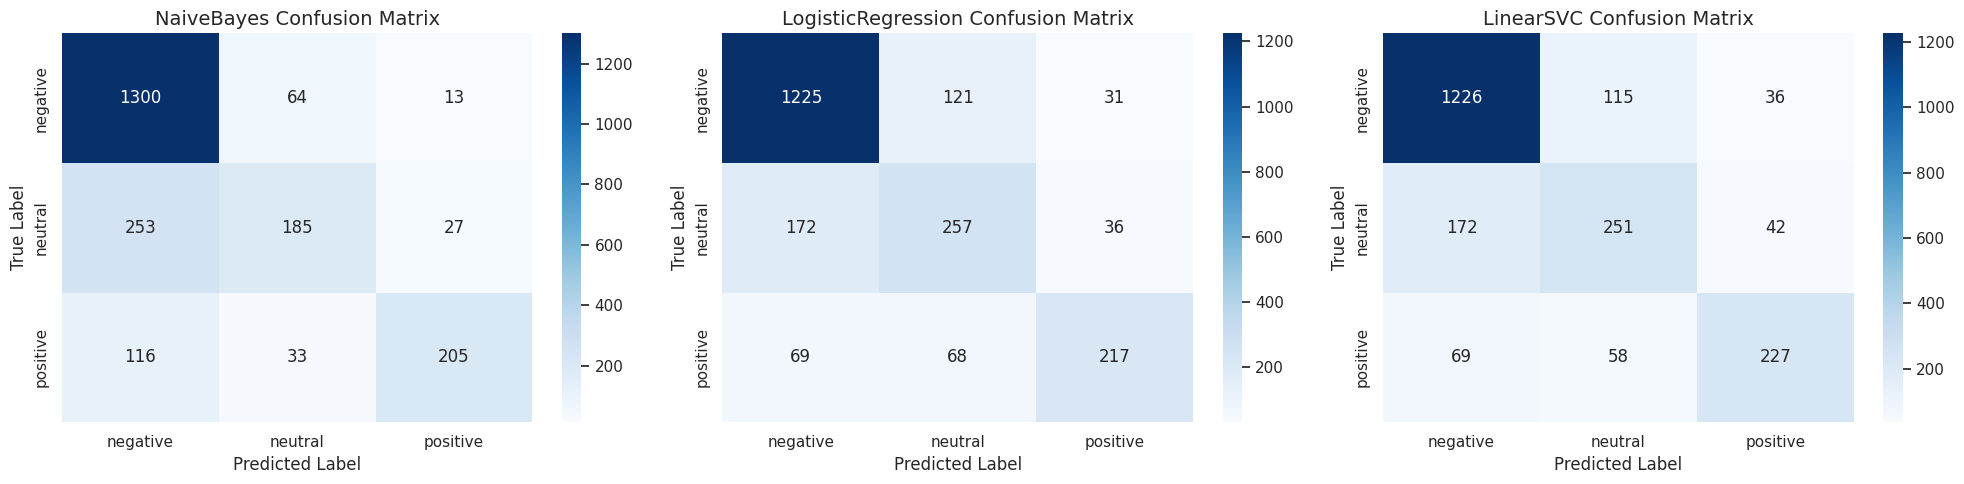

In [7]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, confusion_matrix, f1_score
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Establish and evaluate Dummy Baseline
print('=== Training and Evaluating Baseline Classifier ===')
dummy_clf = DummyClassifier(strategy='most_frequent')
dummy_clf.fit(X_train, y_train)
y_val_dummy_pred = dummy_clf.predict(X_val)

print('\nBaseline (Most Frequent) Validation Classification Report:')
print(classification_report(y_val, y_val_dummy_pred, zero_division=0))
baseline_f1 = f1_score(y_val, y_val_dummy_pred, average='macro')
print(f'Baseline Validation Macro-F1: {baseline_f1:.4f}\n')

# 2. Evaluate Trained Models with detailed metrics
evaluation_results = {}

# We will reuse the best_models dictionary populated in the previous step
for model_name, model in best_models.items():
    print(f'=== Evaluating {model_name} ===')
    y_val_pred = model.predict(X_val)

    # Calculate Metrics
    macro_f1 = f1_score(y_val, y_val_pred, average='macro')
    report = classification_report(y_val, y_val_pred)
    evaluation_results[model_name] = {
        'predictions': y_val_pred,
        'macro_f1': macro_f1,
        'report': report,
        'confusion_matrix': confusion_matrix(y_val, y_val_pred)
    }

    print(report)
    print(f'{model_name} Validation Macro-F1: {macro_f1:.4f}\n')

# 3. Visualize Confusion Matrices for the 3 Machine Learning Models
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
classes = ['negative', 'neutral', 'positive']

for i, (model_name, res) in enumerate(evaluation_results.items()):
    sns.heatmap(
        res['confusion_matrix'],
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=classes,
        yticklabels=classes,
        ax=axes[i]
    )
    axes[i].set_title(f'{model_name} Confusion Matrix')
    axes[i].set_xlabel('Predicted Label')
    axes[i].set_ylabel('True Label')

plt.tight_layout()
plt.show()

## 6.2 Error analysis, interpretability and final test-set evaluation

Sample misclassifications, the most influential TF-IDF features per class (from the Linear SVC coefficients), and a single final evaluation on the untouched test set.

In [8]:
import pandas as pd
import numpy as np
from sklearn.metrics import classification_report, accuracy_score, f1_score

# 1. Error Analysis: Extract sample misclassifications on validation set
best_model_name = 'LinearSVC'
best_model = best_models[best_model_name]
y_val_pred = evaluation_results[best_model_name]['predictions']

val_df = pd.DataFrame({
    'text': X_val,
    'true_label': y_val,
    'pred_label': y_val_pred
})
misclassified = val_df[val_df['true_label'] != val_df['pred_label']]

print('=== Sample Misclassifications (Validation Set) ===')
print(misclassified.head(10).to_string(index=False))

# 2. Extract Top Predictive Features for Interpretability
vectorizer = best_model.named_steps['tfidf']
classifier = best_model.named_steps['clf']
feature_names = np.array(vectorizer.get_feature_names_out())

# Since LinearSVC has multi_class='ovr', coefficients are of shape (n_classes, n_features)
# Classes: ['negative', 'neutral', 'positive']
classes = ['negative', 'neutral', 'positive']
for idx, class_name in enumerate(classes):
    coefs = classifier.coef_[idx]
    top_positive_indices = np.argsort(coefs)[-15:][::-1]
    top_negative_indices = np.argsort(coefs)[:15]

    print(f'\n=== Top 15 Positive Features for {class_name.upper()} ===')
    print(feature_names[top_positive_indices])

    print(f'=== Top 15 Negative Features for {class_name.upper()} ===')
    print(feature_names[top_negative_indices])

# 3. Final Test Set Evaluation
print('\n=== Final Test Set Evaluation (Unseen Data) ===')
y_test_pred = best_model.predict(X_test)
test_acc = accuracy_score(y_test, y_test_pred)
test_macro_f1 = f1_score(y_test, y_test_pred, average='macro')

print(f'Test Accuracy: {test_acc:.4f}')
print(f'Test Macro-F1: {test_macro_f1:.4f}')
print('\nClassification Report on Test Set:')
print(classification_report(y_test, y_test_pred))

=== Sample Misclassifications (Validation Set) ===
                                                                                     text true_label pred_label
thnx response bot seems 'improvement' could easily attained st class service really worth    neutral   negative
                  paid flight wifi austin san diego useable possible get refund conf xxvm   negative    neutral
          ooookay that's silly guess watching oscar purely twitter reaction tonight oscar   negative    neutral
               anything found cleaning plane dc would baggage office even something small    neutral   negative
                                                                really going let get best   negative   positive
                   alright hope jetblue app showing change seat online show want surprise    neutral   negative
                                              flight next two week let's make good memory   positive   negative
                           not possible carryon put c

# Phase 7: Topic Modelling and Model Serialization

Latent Dirichlet Allocation (LDA) is applied to the negative tweets to surface recurring complaint themes. The best sentiment pipeline (preprocessed text -> TF-IDF -> Linear SVC) is saved with Joblib, reloaded and sanity-checked on synthetic inputs.

In [9]:
import joblib
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.feature_extraction.text import TfidfVectorizer

# 1. Filter negative tweets for unsupervised topic modeling
neg_tweets_df = df[df['airline_sentiment'] == 'negative']
print(f'Isolating {len(neg_tweets_df)} negative tweets for topic extraction...')

# 2. Fit TF-IDF Vectorizer on Negative Tweets
lda_vectorizer = TfidfVectorizer(max_df=0.95, min_df=2, stop_words='english')
lda_dtm = lda_vectorizer.fit_transform(neg_tweets_df['cleaned_text'])

# 3. Fit Latent Dirichlet Allocation (LDA) to discover 5 themes
lda = LatentDirichletAllocation(n_components=5, random_state=42)
lda.fit(lda_dtm)

# Print top 10 keywords for each topic
print('\n=== Discovered Negative Topics (Top Keywords) ===')
feature_names = lda_vectorizer.get_feature_names_out()
for topic_idx, topic in enumerate(lda.components_):
    top_features_ind = topic.argsort()[:-11:-1]
    top_features = [feature_names[i] for i in top_features_ind]
    print(f'Topic #{topic_idx + 1}: {", ".join(top_features)}')

# 4. Save/serialize the complete best-performing pipeline
model_filename = 'best_sentiment_pipeline.joblib'
print(f'\nSerializing best LinearSVC pipeline to disk as "{model_filename}"...')
joblib.dump(best_model, model_filename)
print('Pipeline saved successfully.')

# 5. Reload the model and perform verification predictions
print('\nReloading the serialized model pipeline...')
loaded_pipeline = joblib.load(model_filename)

synthetic_test_inputs = [
    "I had a terrible experience, my baggage was completely lost!",
    "The flight attendant was very polite and the service was amazing.",
    "My flight is scheduled for tomorrow at 5 PM."
]

print('\n=== Testing Loaded Pipeline on Synthetic Inputs ===')
for text in synthetic_test_inputs:
    preprocessed = preprocess_text(text)
    pred = loaded_pipeline.predict([preprocessed])[0]
    print(f'Input Text:  "{text}"')
    print(f'Prediction:  {pred}\n')

Isolating 9178 negative tweets for topic extraction...

=== Discovered Negative Topics (Top Keywords) ===
Topic #1: flight, cancelled, problem, flightled, help, time, customer, plane, dm, change
Topic #2: hold, hour, flight, phone, service, customer, help, minute, wait, waiting
Topic #3: flight, cancelled, time, airline, flightled, worst, like, customer, service, fly
Topic #4: flight, gate, bag, ua, plane, delayed, fleet, checked, fleek, delay
Topic #5: flight, hour, plane, delayed, late, bag, delay, waiting, gate, luggage

Serializing best LinearSVC pipeline to disk as "best_sentiment_pipeline.joblib"...
Pipeline saved successfully.

Reloading the serialized model pipeline...

=== Testing Loaded Pipeline on Synthetic Inputs ===
Input Text:  "I had a terrible experience, my baggage was completely lost!"
Prediction:  negative

Input Text:  "The flight attendant was very polite and the service was amazing."
Prediction:  positive

Input Text:  "My flight is scheduled for tomorrow at 5 PM.

# Phase 8: Summary

## Key findings

* **Class imbalance:** of 14,640 tweets, **62.7 %** (9,178) are negative, **21.2 %** (3,099) neutral and **16.1 %** (2,363) positive. A majority-class baseline therefore reaches ~63 % accuracy but only **0.2569** Macro-F1, which is why Macro-F1 is the primary metric.
* **Leakage control:** `negativereason`, `negativereason_confidence` and `negativereason_gold` only exist once a tweet is known to be negative, so they were excluded. The model uses the tweet text only, and the TF-IDF vectorizer is fitted inside the pipeline (training data only).
* **Brand differences:** US Airways (77.7 %) and American (71.0 %) have the highest negative share; Virgin America has the lowest (35.9 %) and the highest positive share (30.2 %).
* **Complaint drivers:** in the labelled `negativereason` column, *Customer Service Issue* (~2,910 tweets) leads, followed by *Late Flight* (~1,665) and *Cancelled Flight* (~847). The LDA topics (delays, cancellations, hold times and phone support, baggage) are heavily overlapping because words such as "flight" appear in every topic.
* **Text length:** negative tweets are longer (avg. 113.9 characters / 19.7 words) than neutral (87.4 / 14.4) and positive (86.1 / 14.0) tweets.

## Model benchmark

| Model | Best parameter | CV Macro-F1 | Validation accuracy | Validation Macro-F1 |
| :--- | :---: | :---: | :---: | :---: |
| Dummy (most frequent) | n/a | n/a | 0.6270 | 0.2569 |
| Multinomial Naive Bayes | `alpha=0.1` | 0.6498 | 0.7696 | 0.6778 |
| Logistic Regression | `C=10` | 0.6938 | 0.7737 | 0.7021 |
| **Linear SVC (selected)** | `C=1.0` | **0.6994** | **0.7760** | **0.7053** |

**Final test set (unseen, 2,196 tweets):** accuracy **0.7837**, Macro-F1 **0.7137**. Validation and test scores are close, so there is no sign of overfitting to the validation set.

## Limitations and next steps

* **Neutral is the hardest class** (test F1 = 0.59). Neutral tweets are most often confused with negative ones.
* **Bag-of-words limits:** sarcasm, short context-free tweets and emojis are not captured. Fine-tuning a transformer (e.g. BERT / RoBERTa) is the natural next step.
* **Negation handling is partial:** the whitelist keeps `not`, `no` and `nor`, but contracted negations such as `didn't`, `wasn't` or `won't` are still in NLTK's stop-word list and are removed. Adding them to the whitelist and retraining is a low-cost improvement.
* **Duplicates:** 36 fully duplicated rows were not dropped; removing them before splitting would make the evaluation slightly cleaner.